# Issue #5: Data Preparation for Association Rule Mining

**Inputs (repository root):** `feature_engineered_sessions.csv` and `feature_engineered_daily.csv` (Issue #12)  
**Outputs (repository root):**
- `association_category_definitions.csv`: every category (item), its rule, meaning and support
- `association_transactions_long.csv`: one row per (session, item); the standard transaction format
- `association_baskets.csv`: one row per session, items joined with `;`
- `association_onehot.csv`: one row per session, one 0/1 column per item (input for Apriori / FP-Growth, e.g. `mlxtend`)
- `association_prep_summary_i5.md`: data-preparation results (generated)

**Idea.** Each charging session is a *transaction*. Its *items* describe the behaviour: when the car arrived, how long it stayed, how much energy it took, how much of the stay was spent charging, and so on. Association rules then find combinations that occur together more often than chance, e.g. *{arrival=morning, day=weekday} → {stay=6-10h}*.

**Design rules**
1. One item per attribute per session (`attribute=value`), so categories within an attribute are mutually exclusive and rules stay readable.
2. Boundaries come from the earlier analysis (e.g. the 6 h short/long valley in Issues #9–#10, the 13–14 kWh default allowance), not from arbitrary quantiles.
3. A missing or unreliable value produces **no item** for that attribute; it never becomes an "unknown" category, which would create meaningless rules.
4. Categories that are empty or present in almost every session (> 95%) carry no information and are removed; rare ones (< 1%) are kept but flagged.

In [1]:
from pathlib import Path
def find_root(marker):
    """Repository root = the folder holding `marker` (this folder or its parent)."""
    for p in [Path.cwd(), Path.cwd().parent]:
        if (p / marker).exists():
            return p
    raise FileNotFoundError(f"{marker} not found in this folder or its parent")
import sys
ROOT = find_root("acn_clean_sessions.csv")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

sess = pd.read_csv(ROOT / "feature_engineered_sessions.csv")
daily = pd.read_csv(ROOT / "feature_engineered_daily.csv", usecols=["date", "is_major_holiday", "holiday_name"])
closure_dates = set(daily.loc[daily["is_major_holiday"] == 1, "date"].astype(str))
print(f"{len(sess):,} sessions, {sess.shape[1]} columns | {sess['arrival_date'].min()} to {sess['arrival_date'].max()}")

31,387 sessions, 59 columns | 2018-04-25 to 2021-09-13


## 1. Available features and which ones become categories

The session table from Issue #12 holds raw measurements, flags and derived features. Columns are selected for association analysis if they describe **charging behaviour** and can be put into a few interpretable groups. The table below records the decision for each candidate.

In [2]:
review = pd.DataFrame([
    ("arrival_hour", "used", "arrival", "When drivers arrive; the morning commuter peak is the strongest pattern in the data"),
    ("dayofweek / is_weekend + daily closures", "used", "day_type", "Weekday, weekend and campus-closure days behave differently (Issues #10, #16)"),
    ("connected_h", "used", "stay", "Plugged-in time; bimodal with a valley near 6 h (short visits vs workday stays)"),
    ("kWhDelivered", "used", "energy", "Energy taken; includes the 13-14 kWh default-allowance spike"),
    ("charging_ratio", "used", "charging_share", "Share of the stay spent charging; the rest is idle time occupying the charger"),
    ("avg_power_kW", "used", "power", "Average charging power; missing where the done-time is unreliable"),
    ("has_user_id", "used", "user", "Claimed (app user) vs unclaimed session; changes with pricing"),
    ("requested_energy_fill_ratio", "used", "request", "Whether the energy the driver asked for was delivered (app users only)"),
    ("is_overnight_stay", "used", "overnight", "Car left on the next calendar day"),
    ("station_is_top_quartile", "used", "station", "Session at one of the busiest quarter of chargers"),
    ("regime", "used", "regime", "Pricing / COVID regime; lets rules be compared between regimes"),
    ("userID, stationID, sessionID", "not used", "", "Identifiers: thousands of values, would give rules about single drivers or chargers"),
    ("ui_milesRequested, ui_WhPerMile, ui_minutesAvailable", "not used", "", "Raw app inputs; summarised by `request`; missing for unclaimed sessions"),
    ("charging_h, idle_h, energy_per_*", "not used", "", "Redundant with stay, energy and charging_share (would create trivial rules)"),
    ("arrival_month, arrival_week", "not used", "", "Season cannot be separated from regime (Issue #10); regime is used instead"),
    ("flags (done_time_missing, power_implausible, ...)", "not used as items", "", "Data-quality flags; used to suppress unreliable items instead"),
], columns=["feature", "decision", "attribute", "reason"])
display(review)

,feature,decision,attribute,reason
0,arrival_hour,used,arrival,When drivers arrive; the morning commuter peak...
1,dayofweek / is_weekend + daily closures,used,day_type,"Weekday, weekend and campus-closure days behav..."
2,connected_h,used,stay,Plugged-in time; bimodal with a valley near 6 ...
3,kWhDelivered,used,energy,Energy taken; includes the 13-14 kWh default-a...
4,charging_ratio,used,charging_share,Share of the stay spent charging; the rest is ...
5,avg_power_kW,used,power,Average charging power; missing where the done...
6,has_user_id,used,user,Claimed (app user) vs unclaimed session; chang...
7,requested_energy_fill_ratio,used,request,Whether the energy the driver asked for was de...
8,is_overnight_stay,used,overnight,Car left on the next calendar day
9,station_is_top_quartile,used,station,Session at one of the busiest quarter of chargers


## 2. Category definitions

| Attribute | Categories (item = `attribute=value`) | Boundaries and source |
|---|---|---|
| `arrival` | night (00–05), morning (06–09), midday (10–13), afternoon (14–17), evening (18–23) | Same blocks as Issue #12 `time_block`; 22–23 h merged into evening (too rare on its own) |
| `day_type` | weekday, weekend, closure | Closure = campus-closure day from Issue #12 (holidays found in the data, winter break); takes precedence |
| `stay` | under_2h, 2-6h, 6-10h, over_10h | 6 h = valley between the short- and long-stay modes (Issues #9–#10); 2 h and 10 h split each mode |
| `energy` | under_2kWh, 2-7kWh, 7-13kWh, 13-14kWh_default, 14-21kWh, over_21kWh | Issue #12 energy bands; 13–14 kWh kept separate (default allowance for unclaimed sessions in R2); 21–35 and > 35 merged |
| `charging_share` | mostly_idle (< 40%), partly_idle (40–80%), mostly_charging (≥ 80%) | Share of plugged-in time spent charging; **no item** when the done-time is missing or inconsistent |
| `power` | low (< 3 kW), medium (3–5 kW), high (≥ 5 kW) | Level-2 chargers deliver up to ~6.6 kW; **no item** when power is implausible or missing |
| `user` | claimed, unclaimed | `has_user_id` |
| `request` | met (≥ 90% of requested kWh), not_met (< 90%) | App users with a request only; **no item** otherwise |
| `overnight` | yes, no | Disconnected on a later calendar day |
| `station` | busy (top 25% by sessions), other | Issue #12 station statistic (descriptive) |
| `regime` | R1_free, R2_free_default, R3_paid, R4_covid | Issue #12 regime dates |

In [3]:
def cut(x, bins, labels, right=False):
    return pd.cut(x, bins=bins, labels=labels, right=right).astype("string")

items = pd.DataFrame(index=sess.index)
items["arrival"] = cut(sess["arrival_hour"], [0, 6, 10, 14, 18, 24], ["night", "morning", "midday", "afternoon", "evening"])
items["day_type"] = np.where(sess["arrival_date"].astype(str).isin(closure_dates), "closure",
                             np.where(sess["is_weekend"].astype(bool), "weekend", "weekday"))
items["stay"] = cut(sess["connected_h"], [0, 2, 6, 10, np.inf], ["under_2h", "2-6h", "6-10h", "over_10h"])
items["energy"] = cut(sess["kWhDelivered"], [0, 2, 7, 13, 14, 21, np.inf],
                      ["under_2kWh", "2-7kWh", "7-13kWh", "13-14kWh_default", "14-21kWh", "over_21kWh"])
reliable_done = ~sess["done_time_missing"].astype(bool) & ~sess["done_time_inconsistent"].astype(bool)
items["charging_share"] = cut(sess["charging_ratio"].where(reliable_done), [0, 0.4, 0.8, 1.0000001],
                              ["mostly_idle", "partly_idle", "mostly_charging"])
items["power"] = cut(sess["avg_power_kW"].where(~sess["power_implausible"].astype(bool) & reliable_done),
                     [0, 3, 5, np.inf], ["low", "medium", "high"])
items["user"] = np.where(sess["has_user_id"].astype(bool), "claimed", "unclaimed")
has_req = sess["requested_energy_fill_ratio"].notna() & sess["has_user_input"].astype(bool)
items["request"] = np.where(~has_req, pd.NA, np.where(sess["requested_energy_fill_ratio"] >= 0.9, "met", "not_met"))
items["overnight"] = np.where(sess["is_overnight_stay"].astype(bool), "yes", "no")
items["station"] = np.where(sess["station_is_top_quartile"].astype(bool), "busy", "other")
items["regime"] = sess["regime"].map({"R1 free": "R1_free", "R2 free, 14 kWh default": "R2_free_default",
                                      "R3 paid": "R3_paid", "R4 COVID period": "R4_covid"})
items = items.astype("string")
assert items["regime"].notna().all(), "unknown regime label"

# Invalid values: anything outside the defined boundaries becomes NaN above; count them per attribute
coverage = pd.DataFrame({"sessions_with_item": items.notna().sum(), "share": items.notna().mean()})
coverage["missing_reason"] = coverage.index.map({
    "charging_share": "done-time missing or inconsistent", "power": "done-time unreliable or power implausible",
    "request": "no app request (unclaimed or no kWh requested)"}).fillna("")
display(coverage.style.format({"share": "{:.1%}"}))

,sessions_with_item,share,missing_reason
arrival,31387,100.0%,
day_type,31387,100.0%,
stay,31387,100.0%,
energy,31387,100.0%,
charging_share,29304,93.4%,done-time missing or inconsistent
power,29263,93.2%,done-time unreliable or power implausible
user,31387,100.0%,
request,16371,52.2%,no app request (unclaimed or no kWh requested)
overnight,31387,100.0%,
station,31387,100.0%,


## 3. Check for empty, invalid and meaningless categories

In [4]:
RARE, COMMON = 0.01, 0.95
n = len(items)
rows = []
DEFINED = {"arrival": ["night", "morning", "midday", "afternoon", "evening"], "day_type": ["weekday", "weekend", "closure"],
           "stay": ["under_2h", "2-6h", "6-10h", "over_10h"],
           "energy": ["under_2kWh", "2-7kWh", "7-13kWh", "13-14kWh_default", "14-21kWh", "over_21kWh"],
           "charging_share": ["mostly_idle", "partly_idle", "mostly_charging"], "power": ["low", "medium", "high"],
           "user": ["claimed", "unclaimed"], "request": ["met", "not_met"], "overnight": ["yes", "no"],
           "station": ["busy", "other"], "regime": ["R1_free", "R2_free_default", "R3_paid", "R4_covid"]}
for attr, values in DEFINED.items():
    vc = items[attr].value_counts()
    undefined = set(vc.index) - set(values)
    assert not undefined, f"{attr}: undefined values {undefined}"
    for v in values:
        c = int(vc.get(v, 0))
        status = "empty" if c == 0 else "too common (>95%)" if c / n > COMMON else "rare (<1%)" if c / n < RARE else "ok"
        rows.append({"attribute": attr, "item": f"{attr}={v}", "sessions": c, "support": c / n, "status": status})
checks = pd.DataFrame(rows)
removed = checks[checks.status.isin(["empty", "too common (>95%)"])]
kept = checks[~checks.index.isin(removed.index)]
display(checks.style.format({"support": "{:.2%}"}).apply(
    lambda r: ["background-color: #fde2e2" if r.status in ("empty", "too common (>95%)") else
               "background-color: #fff4d6" if r.status.startswith("rare") else ""] * len(r), axis=1))
print("Removed:", ", ".join(removed["item"]) or "none", "| rare but kept:", ", ".join(kept.loc[kept.status.str.startswith('rare'), 'item']) or "none")

,attribute,item,sessions,support,status
0,arrival,arrival=night,546,1.74%,ok
1,arrival,arrival=morning,12994,41.40%,ok
2,arrival,arrival=midday,8136,25.92%,ok
3,arrival,arrival=afternoon,4970,15.83%,ok
4,arrival,arrival=evening,4741,15.10%,ok
5,day_type,day_type=weekday,26219,83.53%,ok
6,day_type,day_type=weekend,4761,15.17%,ok
7,day_type,day_type=closure,407,1.30%,ok
8,stay,stay=under_2h,8428,26.85%,ok
9,stay,stay=2-6h,9609,30.61%,ok


Removed: none | rare but kept: none


## 4. Transaction-style representation

Three equivalent formats are saved, so the next issue can use whichever tool it prefers:
- **long:** `transaction_id, item` (one row per item; the classic market-basket layout)
- **baskets:** `transaction_id, items` with items separated by `;`
- **one-hot:** one 0/1 column per item (what `mlxtend.frequent_patterns.apriori` expects)

Context columns (`sessionID`, `arrival_date`, `regime`) are kept in the baskets file so rules can be traced back to sessions or mined per regime.

In [5]:
keep_items = set(kept["item"])
long = (items.stack().rename("value").reset_index().rename(columns={"level_0": "row", "level_1": "attribute"}))
long["item"] = long["attribute"] + "=" + long["value"].astype(str)
long = long[long["item"].isin(keep_items)]
long["transaction_id"] = sess.loc[long["row"], "sessionID"].values
long = long[["transaction_id", "attribute", "item"]].reset_index(drop=True)

baskets = long.groupby("transaction_id", sort=False)["item"].apply(lambda s: ";".join(s)).rename("items").reset_index()
ctx = sess.set_index("sessionID")[["arrival_date", "regime"]]
baskets = baskets.join(ctx, on="transaction_id")
baskets["n_items"] = baskets["items"].str.count(";") + 1

item_order = list(kept["item"])
onehot = (pd.crosstab(long["transaction_id"], long["item"]).reindex(columns=item_order, fill_value=0)
          .reindex(sess["sessionID"]).fillna(0).astype("uint8"))
onehot.index.name = "transaction_id"
print(f"long: {len(long):,} rows | baskets: {len(baskets):,} | one-hot: {onehot.shape[0]:,} x {onehot.shape[1]} items")
display(baskets.head(5))

long: 326,034 rows | baskets: 31,387 | one-hot: 31,387 x 36 items


,transaction_id,items,arrival_date,regime,n_items
0,2_39_78_362_2018-04-25 11:08:04.400812,arrival=night;day_type=weekday;stay=2-6h;energ...,2018-04-25,R1 free,10
1,2_39_95_27_2018-04-25 13:45:09.617470,arrival=morning;day_type=weekday;stay=over_10h...,2018-04-25,R1 free,10
2,2_39_79_380_2018-04-25 13:45:49.962001,arrival=morning;day_type=weekday;stay=6-10h;en...,2018-04-25,R1 free,10
3,2_39_79_379_2018-04-25 14:37:06.460772,arrival=morning;day_type=weekday;stay=6-10h;en...,2018-04-25,R1 free,10
4,2_39_79_381_2018-04-25 14:40:33.638896,arrival=morning;day_type=weekday;stay=6-10h;en...,2018-04-25,R1 free,10


## 5. Is the representation suitable for association analysis?

,check,passed
0,every session is a transaction,True
1,no empty transactions,True
2,at most one item per attribute per transaction,True
3,one-hot matrix is binary,True
4,"long, baskets and one-hot agree",True
5,transaction ids unique,True
6,attributes present in every session have an it...,True
7,no empty or near-constant item kept,True


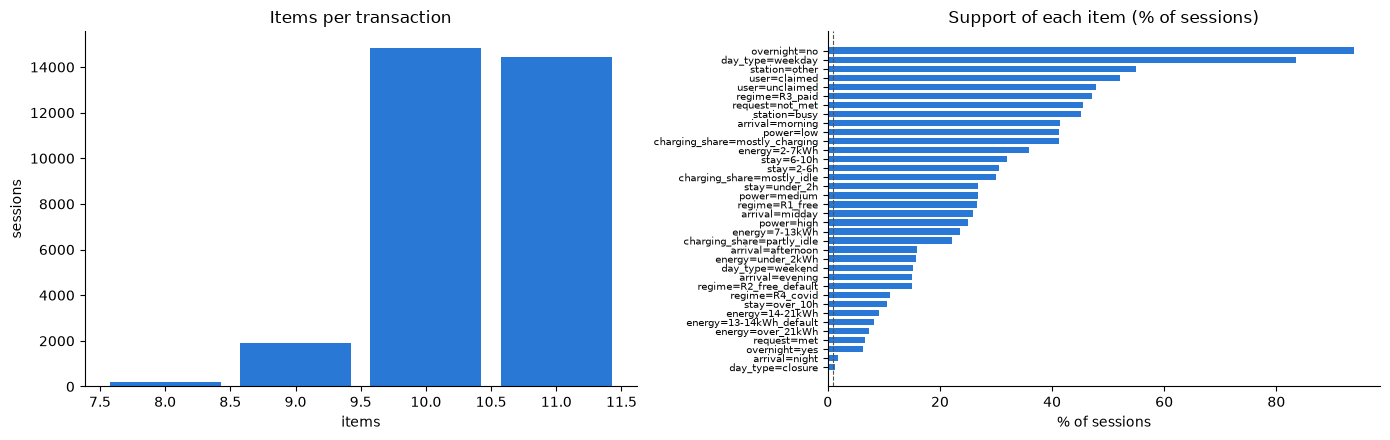

In [6]:
per_attr = long.groupby(["transaction_id", "attribute"]).size()
always = [a for a in DEFINED if coverage.at[a, "share"] == 1 and not any(removed.attribute == a)]   # attributes that lost a category are excluded
v = {
    "every session is a transaction": len(baskets) == len(sess) and onehot.shape[0] == len(sess),
    "no empty transactions": bool((onehot.sum(axis=1) > 0).all()),
    "at most one item per attribute per transaction": bool((per_attr <= 1).all()),
    "one-hot matrix is binary": bool(onehot.isin([0, 1]).all().all()),
    "long, baskets and one-hot agree": int(onehot.values.sum()) == len(long) == int(baskets["n_items"].sum()),
    "transaction ids unique": baskets["transaction_id"].is_unique,
    "attributes present in every session have an item in every session": all(
        (long[long.attribute == a].groupby("transaction_id").size().reindex(sess["sessionID"]).fillna(0) == 1).all() for a in always),
    "no empty or near-constant item kept": not kept.status.isin(["empty", "too common (>95%)"]).any(),
}
verification = pd.DataFrame({"check": list(v), "passed": list(v.values())})
display(verification)
assert verification["passed"].all(), verification[~verification.passed]

size = baskets["n_items"].describe()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].hist(baskets["n_items"], bins=np.arange(baskets.n_items.min() - 0.5, baskets.n_items.max() + 1.5), color="#2a78d6", rwidth=0.85)
axes[0].set(title="Items per transaction", xlabel="items", ylabel="sessions")
k = kept.sort_values("support")
axes[1].barh(k["item"], k["support"] * 100, color=["#eda100" if s.startswith("rare") else "#2a78d6" for s in k.status], height=0.7)
axes[1].axvline(RARE * 100, color="#52514e", ls="--", lw=0.8)
axes[1].set(title="Support of each item (% of sessions)", xlabel="% of sessions"); axes[1].tick_params(axis="y", labelsize=7)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(ROOT / "association_item_support.png", dpi=150, bbox_inches="tight"); plt.show()

**Preview: do the items carry association signal?** Before mining, a quick pairwise check: lift = P(A and B) / (P(A) P(B)). Lift well above 1 for pairs of items from *different* attributes means the data contain associations worth mining. This is only a suitability check; rule mining with minimum support and confidence belongs to the next issue.

In [7]:
X = onehot.values.astype(float)
sup = X.mean(axis=0)
co = (X.T @ X) / len(X)
names = np.array(onehot.columns)
attr_of = np.array([c.split("=")[0] for c in names])
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        if attr_of[i] != attr_of[j] and co[i, j] >= 0.05:
            pairs.append((names[i], names[j], co[i, j], co[i, j] / (sup[i] * sup[j])))
pairs = pd.DataFrame(pairs, columns=["item_a", "item_b", "support", "lift"])
top = pairs.sort_values("lift", ascending=False).head(12)
display(top.style.format({"support": "{:.1%}", "lift": "{:.2f}"}))
print(f"Item pairs with support >= 5%: {len(pairs)}; with lift > 1.5: {int((pairs.lift > 1.5).sum())}; lift < 0.67: {int((pairs.lift < 0.67).sum())}")

,item_a,item_b,support,lift
119,stay=under_2h,regime=R4_covid,6.2%,2.09
274,user=unclaimed,regime=R1_free,26.4%,2.07
152,stay=over_10h,charging_share=mostly_idle,6.4%,2.02
161,energy=under_2kWh,power=low,12.4%,1.92
264,user=claimed,request=met,6.6%,1.92
265,user=claimed,request=not_met,45.5%,1.92
44,arrival=afternoon,stay=under_2h,8.1%,1.90
293,station=busy,regime=R4_covid,9.5%,1.89
56,arrival=evening,stay=under_2h,7.6%,1.88
58,arrival=evening,power=high,6.9%,1.82


Item pairs with support >= 5%: 297; with lift > 1.5: 25; lift < 0.67: 8


## 6. Save the association-analysis dataset and documentation

In [8]:
MEANING = {
    "arrival=night": "Plugged in between 00:00 and 05:59", "arrival=morning": "Plugged in between 06:00 and 09:59 (commuter arrival)",
    "arrival=midday": "Plugged in between 10:00 and 13:59", "arrival=afternoon": "Plugged in between 14:00 and 17:59",
    "arrival=evening": "Plugged in between 18:00 and 23:59",
    "day_type=weekday": "Monday-Friday, not a campus closure", "day_type=weekend": "Saturday or Sunday, not a campus closure",
    "day_type=closure": "Campus-closure day (holiday found in the data, day after Thanksgiving, 24-31 Dec)",
    "stay=under_2h": "Plugged in for less than 2 h (quick top-up)", "stay=2-6h": "2-6 h (short stay, below the 6 h valley)",
    "stay=6-10h": "6-10 h (workday stay)", "stay=over_10h": "10 h or more (very long or overnight stay)",
    "energy=under_2kWh": "Less than 2 kWh (very small top-up, or unclaimed session stopped after 30 min under paid charging)",
    "energy=2-7kWh": "2-7 kWh", "energy=7-13kWh": "7-13 kWh",
    "energy=13-14kWh_default": "13-14 kWh: the default allowance for unclaimed sessions in R2 (Issue #10)",
    "energy=14-21kWh": "14-21 kWh", "energy=over_21kWh": "21 kWh or more (large charge)",
    "charging_share=mostly_idle": "Charging for less than 40% of the stay; the car mostly occupies the charger without charging",
    "charging_share=partly_idle": "Charging for 40-80% of the stay", "charging_share=mostly_charging": "Charging for at least 80% of the stay",
    "power=low": "Average power below 3 kW", "power=medium": "Average power 3-5 kW", "power=high": "Average power 5 kW or more",
    "user=claimed": "Session linked to an app user (userID present)", "user=unclaimed": "No userID (not claimed in the app)",
    "request=met": "App user received at least 90% of the energy requested", "request=not_met": "App user received less than 90% of the energy requested",
    "overnight=yes": "Disconnected on a later calendar day", "overnight=no": "Disconnected on the same day",
    "station=busy": "Charger in the busiest 25% by session count", "station=other": "Any other charger",
    "regime=R1_free": "Free charging, to 31 Aug 2018", "regime=R2_free_default": "Free charging with the 14 kWh default, Sep-Oct 2018",
    "regime=R3_paid": "Paid charging, 1 Nov 2018 to the COVID start", "regime=R4_covid": "COVID period and recovery, from 16 Mar 2020",
}
defs = checks.copy()
defs["value"] = defs["item"].str.split("=").str[1]
defs["meaning"] = defs["item"].map(MEANING)
defs["kept"] = defs["item"].isin(keep_items)
assert defs["meaning"].notna().all(), defs.loc[defs.meaning.isna(), "item"].tolist()
defs = defs[["attribute", "value", "item", "meaning", "sessions", "support", "status", "kept"]]
defs.to_csv(ROOT / "association_category_definitions.csv", index=False)
long.to_csv(ROOT / "association_transactions_long.csv", index=False)
baskets.to_csv(ROOT / "association_baskets.csv", index=False)
onehot.reset_index().to_csv(ROOT / "association_onehot.csv", index=False)
print("Saved association_category_definitions.csv, association_transactions_long.csv, association_baskets.csv, association_onehot.csv")
display(defs.style.format({"support": "{:.1%}"}))

Saved association_category_definitions.csv, association_transactions_long.csv, association_baskets.csv, association_onehot.csv


,attribute,value,item,meaning,sessions,support,status,kept
0,arrival,night,arrival=night,Plugged in between 00:00 and 05:59,546,1.7%,ok,True
1,arrival,morning,arrival=morning,Plugged in between 06:00 and 09:59 (commuter arrival),12994,41.4%,ok,True
2,arrival,midday,arrival=midday,Plugged in between 10:00 and 13:59,8136,25.9%,ok,True
3,arrival,afternoon,arrival=afternoon,Plugged in between 14:00 and 17:59,4970,15.8%,ok,True
4,arrival,evening,arrival=evening,Plugged in between 18:00 and 23:59,4741,15.1%,ok,True
5,day_type,weekday,day_type=weekday,"Monday-Friday, not a campus closure",26219,83.5%,ok,True
6,day_type,weekend,day_type=weekend,"Saturday or Sunday, not a campus closure",4761,15.2%,ok,True
7,day_type,closure,day_type=closure,"Campus-closure day (holiday found in the data, day after Thanksgiving, 24-31 Dec)",407,1.3%,ok,True
8,stay,under_2h,stay=under_2h,Plugged in for less than 2 h (quick top-up),8428,26.9%,ok,True
9,stay,2-6h,stay=2-6h,"2-6 h (short stay, below the 6 h valley)",9609,30.6%,ok,True


## 7. Data-preparation results (generated)

In [9]:
rare_txt = ", ".join(f"`{r.item}` ({r.support:.1%})" for r in kept[kept.status.str.startswith("rare")].itertuples()) or "none"
rem_txt = ", ".join(f"`{r.item}` ({r.status}, {r.support:.1%})" for r in removed.itertuples()) or "none"
miss_txt = "; ".join(f"`{a}` has an item for {coverage.at[a, 'share']:.0%} of sessions ({coverage.at[a, 'missing_reason']})"
                     for a in coverage.index if coverage.at[a, "share"] < 1)
rare_note = ("none." if rare_txt == "none" else rare_txt + ". Kept but flagged: they cannot reach a useful minimum support across all sessions, but can within a regime.")
top3 = "; ".join(f"{{{r.item_a}, {r.item_b}}} lift {r.lift:.2f} (support {r.support:.0%})" for r in top.head(3).itertuples())
text = f"""# Issue #5: Association-analysis data preparation (generated)

- **Transactions:** {len(baskets):,} charging sessions ({sess['arrival_date'].min()} to {sess['arrival_date'].max()}), one transaction each.
- **Items:** {len(kept)} categories from {kept['attribute'].nunique()} behaviour attributes (arrival time, day type, stay length, energy, charging share, power, user, request outcome, overnight, station, regime). Definitions and meanings: `association_category_definitions.csv`.
- **Transaction size:** {size['min']:.0f}-{size['max']:.0f} items (median {size['50%']:.0f}); at most one item per attribute, so categories are mutually exclusive.
- **Missing values produce no item, never an "unknown" category:** {miss_txt}.
- **Removed categories (empty or > 95% of sessions):** {rem_txt}.
- **Rare categories (< 1%):** {rare_note}
- **Verification:** all {len(verification)} checks passed (no empty transactions, one-hot matrix binary, the three formats agree, one item per attribute).
- **Association signal:** {len(pairs)} item pairs from different attributes reach 5% support; {int((pairs.lift > 1.5).sum())} have lift > 1.5. Strongest: {top3}.
- **Files:** `association_transactions_long.csv` (long format), `association_baskets.csv` (one row per session, with date and regime), `association_onehot.csv` ({onehot.shape[1]} item columns, for Apriori / FP-Growth).
- **Notes for mining:** the `regime` item makes it possible to mine all sessions together or each regime separately; pricing changed behaviour strongly, so rules that hold only in one regime should be reported with that regime. The `energy=13-14kWh_default` and `user=unclaimed` items are linked by design in R2 (default allowance), and `energy=under_2kWh` with `user=unclaimed` in R3 (30-minute stop); such rules reflect operator policy, not driver choice.
"""
(ROOT / "association_prep_summary_i5.md").write_text(text, encoding="utf-8")
display(Markdown(text))

# Issue #5: Association-analysis data preparation (generated)

- **Transactions:** 31,387 charging sessions (2018-04-25 to 2021-09-13), one transaction each.
- **Items:** 36 categories from 11 behaviour attributes (arrival time, day type, stay length, energy, charging share, power, user, request outcome, overnight, station, regime). Definitions and meanings: `association_category_definitions.csv`.
- **Transaction size:** 8-11 items (median 10); at most one item per attribute, so categories are mutually exclusive.
- **Missing values produce no item, never an "unknown" category:** `charging_share` has an item for 93% of sessions (done-time missing or inconsistent); `power` has an item for 93% of sessions (done-time unreliable or power implausible); `request` has an item for 52% of sessions (no app request (unclaimed or no kWh requested)).
- **Removed categories (empty or > 95% of sessions):** none.
- **Rare categories (< 1%):** none.
- **Verification:** all 8 checks passed (no empty transactions, one-hot matrix binary, the three formats agree, one item per attribute).
- **Association signal:** 297 item pairs from different attributes reach 5% support; 25 have lift > 1.5. Strongest: {stay=under_2h, regime=R4_covid} lift 2.09 (support 6%); {user=unclaimed, regime=R1_free} lift 2.07 (support 26%); {stay=over_10h, charging_share=mostly_idle} lift 2.02 (support 6%).
- **Files:** `association_transactions_long.csv` (long format), `association_baskets.csv` (one row per session, with date and regime), `association_onehot.csv` (36 item columns, for Apriori / FP-Growth).
- **Notes for mining:** the `regime` item makes it possible to mine all sessions together or each regime separately; pricing changed behaviour strongly, so rules that hold only in one regime should be reported with that regime. The `energy=13-14kWh_default` and `user=unclaimed` items are linked by design in R2 (default allowance), and `energy=under_2kWh` with `user=unclaimed` in R3 (30-minute stop); such rules reflect operator policy, not driver choice.


## Issue #5 checklist → where it is done

| Task | Section |
|---|---|
| Review the available cleaned and engineered charging features | 1 |
| Identify charging attributes that can form meaningful behavioural categories | 1 |
| Define suitable categorical or binned charging conditions | 2 |
| Create meaningful charging-behaviour categories | 2 |
| Convert the selected features into a transaction-style format | 4 |
| Verify that the transaction representation is suitable for association analysis | 5 |
| Check for empty, invalid or meaningless categories | 2 (invalid → no item), 3 |
| Document the meaning of each category | 2, 6 (`association_category_definitions.csv`) |
| Save the prepared association-analysis dataset | 6 |

**Deliverables:** this notebook, `association_category_definitions.csv`, `association_transactions_long.csv`, `association_baskets.csv`, `association_onehot.csv`, `association_item_support.png`, `association_prep_summary_i5.md`.